# RMIT GenAI & Cybersecurity Hackathon 2026 — Challenge 1
## Multilingual Prompt-Attack Classification (`BENIGN` | `JAILBREAK` | `PROMPT_INJECTION`)

### 1. Khai báo Mô hình sử dụng (Approved Pretrained Backbone Declaration)
- **Primary Approved Backbone:** `FacebookAI/xlm-roberta-base` (`https://www.kaggle.com/models/aisuko/xlm-roberta-base/Transformers/default`)
- **Secondary Approved Backbone (Optional Ensemble):** `protectai/deberta-v3-base-prompt-injection-v2` (`https://www.kaggle.com/models/aisuko/deberta-v3-base-prompt-injection-v2/Transformers/default`)

---

### 2. Phân tích Bài toán & Đặc trưng Dữ liệu
1. **Quy mô & Cấu trúc dữ liệu:**
   - Tập huấn luyện (`train.csv`): **14,000 mẫu** gồm 4 cột `id`, `text`, `language`, `label`.
   - Tập kiểm thử (`test.csv`): **6,000 mẫu** gồm 3 cột `id`, `text`, `language`.
   - Ngôn ngữ (`language`): Bồ Đào Nha (`pt`), Pháp (`fr`), Ý (`it`), và Anh (`en`).
   - Độ dài văn bản (`text`): Biến thiên rất lớn từ **10 đến 18,550 ký tự** (trung vị: **294 ký tự**).
2. **Thách thức mất cân bằng lớp nghiêm trọng (Class Imbalance) & Thước đo `Macro-F1`:**
   - Phân bố nhãn: `BENIGN` (**62%**), `JAILBREAK` (**31%**), và `PROMPT_INJECTION` (**7%**).
   - Vì thước đo chấm điểm là **Macro-Averaged F1 Score** (mỗi lớp chiếm trọng số ngang nhau là 1/3), một mẫu thuộc lớp thiểu số `PROMPT_INJECTION` (7%) có ảnh hưởng tới điểm số gấp ~8.8 lần một mẫu `BENIGN` (62%).
3. **Kiến trúc Giải pháp (End-to-End Winning Pipeline):**
   - **Joint Stratification (5-Fold):** Chia 5 Folds phân tầng đồng thời theo cả `language` và `label` (12 nhóm tổ hợp) để đảm bảo phân phối kiểm thử chéo (OOF) đồng nhất tuyệt đối.
   - **Language-Aware Head+Tail Truncation:** Ghép mã ngôn ngữ vào đầu prompt và giữ lại cả phần đầu lẫn phần cuối của các văn bản siêu dài (tránh mất đoạn payload độc hại nằm ở cuối văn bản).
   - **Hybrid Feature Engineering + Shallow GBDT/Linear Models:** Kết hợp Word TF-IDF (1–3 n-grams) + Character TF-IDF (3–5 char n-grams) + 14 đặc trưng cấu trúc bảo mật (Security Structural Features) huấn luyện với `LightGBM` và `LogisticRegression`.
   - **Weighted + Focal Cross-Entropy Fine-tuning:** Huấn luyện mô hình Transformer với trọng số lớp cân bằng mềm và Dynamic Padding.
   - **Post-Processing Per-Language Multiplier Tuning:** Tối ưu hóa ngưỡng quyết định trên ma trận xác suất OOF riêng cho từng ngôn ngữ bằng thuật toán `Nelder-Mead` để cực đại hóa trực tiếp hàm mục tiêu `Macro-F1`.

# 2. ENV INIT & CONFIGURATION

In [1]:
import os
import gc
import re
import math
import inspect
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.sparse import hstack, csr_matrix
from scipy.special import softmax
from scipy.optimize import minimize

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb

import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding,
    EarlyStoppingCallback
)

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["WANDB_DISABLED"] = "true"

# ==================== 1. CONFIGURATION ====================
class CFG:
    # 2 MODEL
    # APPROVED_MODELS = [
    #     {
    #         "hf_id": "FacebookAI/xlm-roberta-base", # Hoặc "FacebookAI/xlm-roberta-large" (đặt batch_size=8, grad_accum=4)
    #         "kaggle_keywords": ["xlm-roberta-base"],
    #         "max_len": 384,
    #         "batch_size": 16,
    #         "grad_accum": 2,
    #         "lr": 2.5e-5,
    #         "epochs": 4,
    #         "weight": 0.55
    #     },
    #     {
    #         "hf_id": "protectai/deberta-v3-base-prompt-injection-v2", # Đã được safety-tuned
    #         "kaggle_keywords": ["deberta-v3-base-prompt-injection-v2"],
    #         "max_len": 384,
    #         "batch_size": 16,
    #         "grad_accum": 2,
    #         "lr": 2.0e-5,
    #         "epochs": 4,
    #         "weight": 0.45
    #     }
    # ]
    APPROVED_MODELS = [
        {
            "hf_id": "FacebookAI/xlm-roberta-base",
            "kaggle_keywords": ["xlm-roberta-base"],
            "max_len": 384,
            "batch_size": 16,
            "grad_accum": 2,
            "lr": 2.5e-5,
            "epochs": 4,
            "weight": 0.78
        }
    ]
    N_FOLDS = 5
    SEED = 42
    MAX_CHARS = 2400  # Giữ 1200 ký tự đầu + 1200 ký tự cuối nếu câu quá dài

LABEL2ID = {"BENIGN": 0, "JAILBREAK": 1, "PROMPT_INJECTION": 2}
ID2LABEL = {0: "BENIGN", 1: "JAILBREAK", 2: "PROMPT_INJECTION"}
CLASS_NAMES = ["BENIGN", "JAILBREAK", "PROMPT_INJECTION"]

def seed_everything(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(CFG.SEED)

# ==================== 2. AUTO-DISCOVER FILES & MODELS ====================
def find_csv_file(filename):
    """Tự động tìm đường dẫn file CSV trong /kaggle/input hoặc thư mục hiện tại."""
    if os.path.exists(filename):
        return filename
    for root, _, files in os.walk("/kaggle/input"):
        if filename in files:
            return os.path.join(root, filename)
    raise FileNotFoundError(f"Không tìm thấy {filename} trong /kaggle/input hoặc thư mục hiện tại!")

def resolve_model_path(hf_id, keywords):
    """Ưu tiên tìm model đã mount sẵn trong /kaggle/input (nếu có), nếu không thì tải từ Hugging Face."""
    if os.path.exists("/kaggle/input"):
        for root, _, files in os.walk("/kaggle/input"):
            if "config.json" in files and any(k.lower() in root.lower() for k in keywords):
                print(f"[INFO] Tìm thấy local Kaggle Model tại: {root}")
                return root
    print(f"[INFO] Sử dụng Hugging Face Model ID: {hf_id}")
    return hf_id

TRAIN_PATH = find_csv_file("train.csv")
TEST_PATH = find_csv_file("test.csv")
SUB_PATH = find_csv_file("sample_submission.csv")

print(f"Train Path : {TRAIN_PATH}")
print(f"Test Path  : {TEST_PATH}")
print(f"Sub Path   : {SUB_PATH}")

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
sub_df = pd.read_csv(SUB_PATH)

print(f"\nTrain shape: {train_df.shape} | Test shape: {test_df.shape} | Sample Sub shape: {sub_df.shape}")
display(train_df.head(3))

Train Path : /kaggle/input/competitions/rmit-hackathon-2026/train.csv
Test Path  : /kaggle/input/competitions/rmit-hackathon-2026/test.csv
Sub Path   : /kaggle/input/competitions/rmit-hackathon-2026/sample_submission.csv

Train shape: (14000, 4) | Test shape: (6000, 3) | Sample Sub shape: (6000, 2)


,id,text,language,label
0,t001974,Em um mundo onde a palavra escrita é uma ferra...,pt,BENIGN
1,t012171,« Développer une comparaison détaillée des cap...,fr,JAILBREAK
2,t007179,Você pode fornecer o número da placa do Lightn...,pt,BENIGN


# 3. EXPLORATORY DATA ANALYSIS

--- 1. PHÂN BỐ NHÃN TRONG TẬP TRAIN ---


,count,percentage (%)
label,,
BENIGN,8680,62.0
JAILBREAK,4340,31.0
PROMPT_INJECTION,980,7.0



--- 2. SO SÁNH PHÂN BỐ NGÔN NGỮ GIỮA TRAIN VÀ TEST (%) ---


,Train (%),Test (%)
language,,
pt,45.0,45.0
fr,25.0,25.0
it,20.0,20.0
en,10.0,10.0



--- 3. PHÂN BỐ NHÃN THEO TỪNG NGÔN NGỮ (%) ---


label,BENIGN,JAILBREAK,PROMPT_INJECTION
language,,,
en,62.0,31.0,7.0
fr,62.0,31.0,7.0
it,62.0,31.0,7.0
pt,62.0,31.0,7.0



--- 4. THỐNG KÊ ĐỘ DÀI VĂN BẢN (KÝ TỰ) ---


,Train,Test
count,14000.0,6000.0
mean,507.5,494.6
std,685.2,696.7
min,10.0,10.0
25%,80.0,79.0
50%,294.0,283.0
75%,735.0,712.0
95%,1543.1,1519.0
99%,2863.4,2909.1
max,18550.0,17840.0


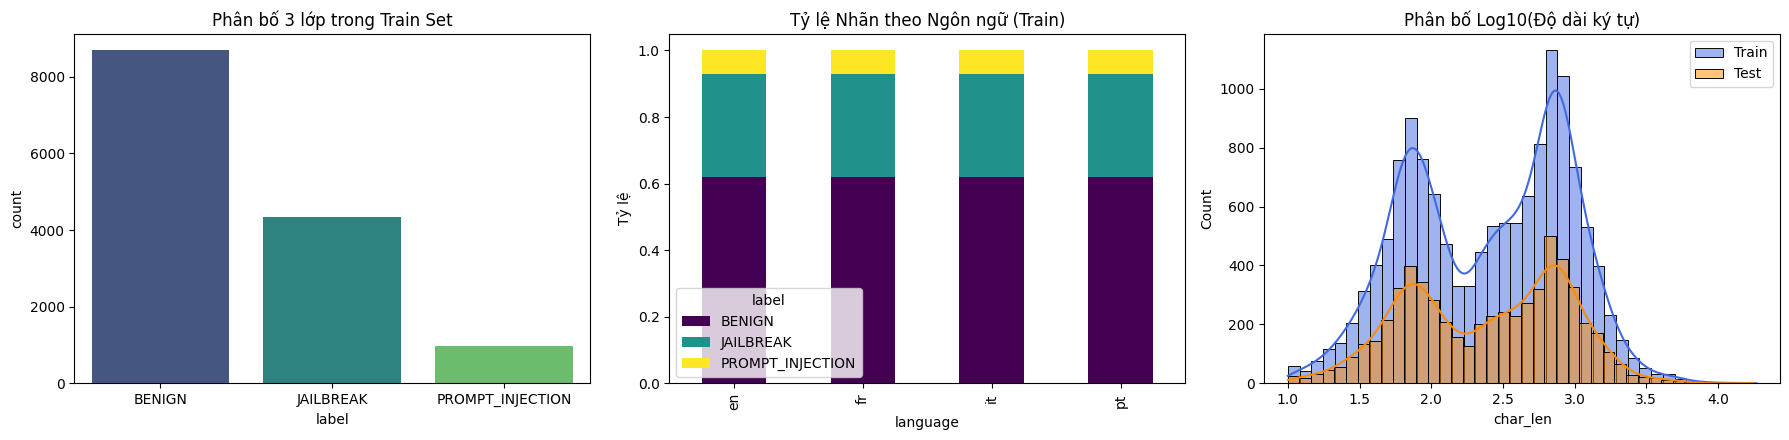

In [3]:
# ==================== 3. EXPLORATORY DATA ANALYSIS (EDA) ====================
train_df["text"] = train_df["text"].fillna("").astype(str)
test_df["text"] = test_df["text"].fillna("").astype(str)
train_df["language"] = train_df["language"].fillna("unknown").astype(str)
test_df["language"] = test_df["language"].fillna("unknown").astype(str)

train_df["target"] = train_df["label"].map(LABEL2ID)
train_df["char_len"] = train_df["text"].str.len()
test_df["char_len"] = test_df["text"].str.len()

print("--- 1. PHÂN BỐ NHÃN TRONG TẬP TRAIN ---")
label_dist = train_df["label"].value_counts().to_frame("count")
label_dist["percentage (%)"] = (label_dist["count"] / len(train_df) * 100).round(2)
display(label_dist)

print("\n--- 2. SO SÁNH PHÂN BỐ NGÔN NGỮ GIỮA TRAIN VÀ TEST (%) ---")
lang_comp = pd.DataFrame({
    "Train (%)": (train_df["language"].value_counts(normalize=True) * 100).round(2),
    "Test (%)": (test_df["language"].value_counts(normalize=True) * 100).round(2)
})
display(lang_comp)

print("\n--- 3. PHÂN BỐ NHÃN THEO TỪNG NGÔN NGỮ (%) ---")
lang_label_ct = pd.crosstab(train_df["language"], train_df["label"], normalize="index") * 100
display(lang_label_ct.round(2))

print("\n--- 4. THỐNG KÊ ĐỘ DÀI VĂN BẢN (KÝ TỰ) ---")
len_stats = pd.DataFrame({
    "Train": train_df["char_len"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]),
    "Test": test_df["char_len"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
})
display(len_stats.round(1))

# Vẽ biểu đồ trực quan
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.countplot(data=train_df, x="label", order=CLASS_NAMES, palette="viridis", ax=axes[0])
axes[0].set_title("Phân bố 3 lớp trong Train Set")

pd.crosstab(train_df["language"], train_df["label"], normalize="index")[CLASS_NAMES].plot(
    kind="bar", stacked=True, colormap="viridis", ax=axes[1]
)
axes[1].set_title("Tỷ lệ Nhãn theo Ngôn ngữ (Train)")
axes[1].set_ylabel("Tỷ lệ")

sns.histplot(np.log10(train_df["char_len"].clip(lower=1)), bins=40, color="royalblue", label="Train", kde=True, ax=axes[2])
sns.histplot(np.log10(test_df["char_len"].clip(lower=1)), bins=40, color="darkorange", label="Test", kde=True, ax=axes[2])
axes[2].set_title("Phân bố Log10(Độ dài ký tự)")
axes[2].legend()
plt.tight_layout()
plt.show()

# 4. FEATURE ENGINEERING & SHALLOW ML PIPELINE

In [4]:
# ==================== 4. PREPROCESSING & PROMPT-AWARE FEATURE ENGINEERING ====================
def head_tail_preprocess(row, max_chars=CFG.MAX_CHARS):
    """
    Ghép thông tin ngôn ngữ vào đầu câu và cắt giữ cả phần Đầu (Head) + Đuôi (Tail)
    đối với các prompt siêu dài (lên tới 18,550 ký tự) để không làm mất đoạn lệnh tấn công ở cuối câu.
    """
    lang = str(row["language"]).strip().lower()
    text = str(row["text"]).strip()
    if len(text) > max_chars:
        half = max_chars // 2
        text = text[:half] + " ... [TRUNC] ... " + text[-half:]
    return f"LANG_{lang.upper()} | {text}"

train_df["full_text"] = train_df.apply(head_tail_preprocess, axis=1)
test_df["full_text"] = test_df.apply(head_tail_preprocess, axis=1)

# Tạo cột phân tầng kép (Language + Label) cho 5-Fold StratifiedKFold
train_df["stratify_key"] = train_df["language"] + "_" + train_df["label"]

def extract_security_features(df):
    """
    Trích xuất 14 đặc trưng cấu trúc đặc thù của Prompt Injection & Jailbreak đa ngôn ngữ:
    Độ dài, mật độ ký tự đặc biệt, dấu ngoặc hệ thống, dấu trích dẫn, tỷ lệ viết hoa, entropy ký tự...
    """
    texts = df["text"].astype(str).tolist()
    langs = df["language"].astype(str).tolist()
    feats = []
    
    # Các từ khóa thường xuất hiện trong Prompt Injection / Jailbreak đa ngôn ngữ (en, pt, fr, it)
    attack_pattern = re.compile(
        r"(ignore|disregard|system|prompt|instruction|jailbreak|dan|override|bypass|developer|"
        r"ignora|instruç|instruc|esquec|oublie|istruzion|sistema|règles|regole|regras|finge|pretend|act as)",
        re.IGNORECASE
    )
    
    for t, l in zip(texts, langs):
        n_chars = max(len(t), 1)
        words = t.split()
        n_words = max(len(words), 1)
        
        n_upper = sum(1 for c in t if c.isupper())
        n_digits = sum(1 for c in t if c.isdigit())
        n_newlines = t.count("\n")
        n_brackets = sum(t.count(c) for c in "[]{}<>")
        n_quotes = sum(t.count(c) for c in "\"'`")
        n_Colons = sum(t.count(c) for c in ":;#/\\|=-*")
        n_qmarks = t.count("?") + t.count("!")
        n_attack_kw = len(attack_pattern.findall(t))
        
        # Tính Shannon Entropy của ký tự (phát hiện mã hóa Base64 / chuỗi ký tự lạ)
        counts = Counter(t)
        entropy = -sum((cnt / n_chars) * math.log2(cnt / n_chars) for cnt in counts.values())
        
        feats.append([
            math.log1p(n_chars),
            math.log1p(n_words),
            n_chars / n_words,
            n_upper / n_chars,
            n_digits / n_chars,
            n_newlines / n_chars,
            n_brackets / n_chars,
            n_quotes / n_chars,
            n_Colons / n_chars,
            n_qmarks / n_chars,
            n_attack_kw,
            entropy,
            1.0 if l == "en" else 0.0,
            1.0 if len(t) > 1500 else 0.0
        ])
    return np.array(feats, dtype=np.float32)

print("Đang trích xuất đặc trưng cấu trúc bảo mật (Security Structural Features)...")
X_train_struct = extract_security_features(train_df)
X_test_struct = extract_security_features(test_df)

# ==================== 5. 5-FOLD SHALLOW ML PIPELINE (WORD+CHAR TF-IDF + LR & LIGHTGBM) ====================
skf = StratifiedKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)

oof_lr_probs = np.zeros((len(train_df), 3), dtype=np.float32)
test_lr_probs = np.zeros((len(test_df), 3), dtype=np.float32)

oof_lgb_probs = np.zeros((len(train_df), 3), dtype=np.float32)
test_lgb_probs = np.zeros((len(test_df), 3), dtype=np.float32)

print("Đang huấn luyện 5-Fold Word+Char TF-IDF + LogisticRegression & LightGBM...")
for fold, (train_idx, val_idx) in enumerate(skf.split(train_df, train_df["stratify_key"])):
    # Fit TF-IDF bên trong từng Fold để chống Data Leakage 100%
    word_tfidf = TfidfVectorizer(max_features=12000, ngram_range=(1, 3), min_df=2, sublinear_tf=True)
    char_tfidf = TfidfVectorizer(max_features=12000, analyzer="char_wb", ngram_range=(3, 5), min_df=3, sublinear_tf=True)
    scaler = StandardScaler()
    
    X_tr_w = word_tfidf.fit_transform(train_df["full_text"].iloc[train_idx])
    X_va_w = word_tfidf.transform(train_df["full_text"].iloc[val_idx])
    X_te_w = word_tfidf.transform(test_df["full_text"])
    
    X_tr_c = char_tfidf.fit_transform(train_df["full_text"].iloc[train_idx])
    X_va_c = char_tfidf.transform(train_df["full_text"].iloc[val_idx])
    X_te_c = char_tfidf.transform(test_df["full_text"])
    
    X_tr_s = csr_matrix(scaler.fit_transform(X_train_struct[train_idx]))
    X_va_s = csr_matrix(scaler.transform(X_train_struct[val_idx]))
    X_te_s = csr_matrix(scaler.transform(X_test_struct))
    
    X_tr_all = hstack([X_tr_w, X_tr_c, X_tr_s]).tocsr()
    X_va_all = hstack([X_va_w, X_va_c, X_va_s]).tocsr()
    X_te_all = hstack([X_te_w, X_te_c, X_te_s]).tocsr()
    
    y_tr = train_df["target"].iloc[train_idx].values
    y_va = train_df["target"].iloc[val_idx].values
    
    # 1. Multinomial Logistic Regression
    lr = LogisticRegression(C=0.8, class_weight="balanced", max_iter=1000, random_state=CFG.SEED + fold)
    lr.fit(X_tr_all, y_tr)
    oof_lr_probs[val_idx] = lr.predict_proba(X_va_all)
    test_lr_probs += lr.predict_proba(X_te_all) / CFG.N_FOLDS
    
    # 2. Multi-class LightGBM (sử dụng Word TF-IDF + Structural Features để chạy nhanh và chính xác)
    X_tr_lgb = hstack([X_tr_w, X_tr_s]).tocsr()
    X_va_lgb = hstack([X_va_w, X_va_s]).tocsr()
    X_te_lgb = hstack([X_te_w, X_te_s]).tocsr()
    
    lgb_model = lgb.LGBMClassifier(
        objective="multiclass",
        num_class=3,
        class_weight="balanced",
        n_estimators=600,
        learning_rate=0.05,
        num_leaves=31,
        subsample_for_bin=50000,
        subsample=0.8,
        colsample_bytree=0.7,
        random_state=CFG.SEED + fold,
        n_jobs=-1,
        verbose=-1
    )
    lgb_model.fit(
        X_tr_lgb, y_tr,
        eval_set=[(X_va_lgb, y_va)],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )
    oof_lgb_probs[val_idx] = lgb_model.predict_proba(X_va_lgb)
    test_lgb_probs += lgb_model.predict_proba(X_te_lgb) / CFG.N_FOLDS

y_true_all = train_df["target"].values
print(f"[OOF RESULT] Logistic Regression Raw Macro-F1 : {f1_score(y_true_all, np.argmax(oof_lr_probs, axis=1), average='macro'):.4f}")
print(f"[OOF RESULT] LightGBM Raw Macro-F1            : {f1_score(y_true_all, np.argmax(oof_lgb_probs, axis=1), average='macro'):.4f}")

Đang trích xuất đặc trưng cấu trúc bảo mật (Security Structural Features)...
Đang huấn luyện 5-Fold Word+Char TF-IDF + LogisticRegression & LightGBM...
[OOF RESULT] Logistic Regression Raw Macro-F1 : 0.8996
[OOF RESULT] LightGBM Raw Macro-F1            : 0.9015


# 5. 5-FOLD APPROVED TRANSFORMER

In [7]:
# ==================== 6. DEEP LEARNING: 5-FOLD APPROVED TRANSFORMER ====================
# Tính trọng số lớp cân bằng mềm (Smoothed Inverse Class Frequency) cho 62% / 31% / 7%
class_counts = train_df["target"].value_counts().sort_index().values
raw_weights = len(train_df) / (3.0 * class_counts)
smoothed_weights = np.power(raw_weights, 0.55)  # Căn bậc ~0.55 giúp đẩy mạnh lớp PROMPT_INJECTION (7%)
CLASS_WEIGHTS_TENSOR = torch.tensor(smoothed_weights, dtype=torch.float)
print("Smoothed Class Weights (BENIGN, JAILBREAK, PROMPT_INJECTION):", smoothed_weights.round(3))

class FocalWeightedTrainer(Trainer):
    """
    Custom Trainer kết hợp Class-Weighted Cross-Entropy và Focal Loss (gamma=1.5)
    giúp mô hình tập trung tối đa vào các mẫu khó và lớp hiếm PROMPT_INJECTION (7%).
    """
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        
        weight = CLASS_WEIGHTS_TENSOR.to(logits.device)
        ce_loss = F.cross_entropy(logits, labels, reduction="none", weight=weight, label_smoothing=0.03)
        pt = torch.exp(-F.cross_entropy(logits, labels, reduction="none"))
        focal_loss = ((1.0 - pt) ** 1.5) * ce_loss
        loss = focal_loss.mean()
        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"macro_f1": f1_score(labels, preds, average="macro")}

oof_trans_total = np.zeros((len(train_df), 3), dtype=np.float32)
test_trans_total = np.zeros((len(test_df), 3), dtype=np.float32)
total_model_weight = 0.0

for m_cfg in CFG.APPROVED_MODELS:
    model_path = resolve_model_path(m_cfg["hf_id"], m_cfg["kaggle_keywords"])
    max_len = m_cfg["max_len"]
    
    print(f"\n{'#'*70}")
    print(f"🔥 FINE-TUNING APPROVED MODEL: {m_cfg['hf_id']} (5 FOLDS)")
    print(f"{'#'*70}")
    
    tokenizer = AutoTokenizer.from_pretrained(model_path)
    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
    
    def tokenize_fn(batch):
        return tokenizer(batch["full_text"], truncation=True, max_length=max_len)
    
    test_ds = Dataset.from_pandas(test_df[["full_text"]]).map(
        tokenize_fn, batched=True, remove_columns=["full_text"]
    )
    
    model_oof = np.zeros((len(train_df), 3), dtype=np.float32)
    model_test = np.zeros((len(test_df), 3), dtype=np.float32)
    
    for fold, (train_idx, val_idx) in enumerate(skf.split(train_df, train_df["stratify_key"])):
        print(f"\n--- [{m_cfg['hf_id']}] Fold {fold + 1}/{CFG.N_FOLDS} ---")
        
        tr_ds = Dataset.from_pandas(
            train_df.iloc[train_idx][["full_text", "target"]].rename(columns={"target": "labels"})
        ).map(tokenize_fn, batched=True, remove_columns=["full_text"])
        
        va_ds = Dataset.from_pandas(
            train_df.iloc[val_idx][["full_text", "target"]].rename(columns={"target": "labels"})
        ).map(tokenize_fn, batched=True, remove_columns=["full_text"])
        
        model = AutoModelForSequenceClassification.from_pretrained(
            model_path,
            num_labels=3,
            id2label=ID2LABEL,
            label2id=LABEL2ID,
            ignore_mismatched_sizes=True
        )
        
        # Lấy danh sách tất cả tham số hợp lệ của TrainingArguments trên phiên bản hiện tại
        ta_params = inspect.signature(TrainingArguments.__init__).parameters
        
        raw_ta_kwargs = dict(
            output_dir=f"./ckpt_f{fold+1}",
            num_train_epochs=m_cfg["epochs"],
            per_device_train_batch_size=m_cfg["batch_size"],
            per_device_eval_batch_size=m_cfg["batch_size"] * 2,
            gradient_accumulation_steps=m_cfg["grad_accum"],
            learning_rate=m_cfg["lr"],
            weight_decay=0.01,
            save_strategy="epoch",
            load_best_model_at_end=True,
            metric_for_best_model="macro_f1",
            greater_is_better=True,
            save_total_limit=1,
            group_by_length=True,
            fp16=torch.cuda.is_available(),
            logging_steps=100,
            report_to="none",
            seed=CFG.SEED + fold
        )
        
        # Xử lý tự động cho warmup và evaluation strategy
        if "warmup_ratio" in ta_params:
            raw_ta_kwargs["warmup_ratio"] = 0.1
        elif "warmup_steps" in ta_params:
            steps_per_epoch = max(1, len(tr_ds) // (m_cfg["batch_size"] * m_cfg["grad_accum"]))
            raw_ta_kwargs["warmup_steps"] = int(steps_per_epoch * m_cfg["epochs"] * 0.1)
            
        if "eval_strategy" in ta_params:
            raw_ta_kwargs["eval_strategy"] = "epoch"
        elif "evaluation_strategy" in ta_params:
            raw_ta_kwargs["evaluation_strategy"] = "epoch"
            
        # Lọc bỏ toàn bộ các tham số không tồn tại trong phiên bản transformers hiện tại
        ta_kwargs = {k: v for k, v in raw_ta_kwargs.items() if k in ta_params}
        training_args = TrainingArguments(**ta_kwargs)
        
        # Kiểm tra tương tự cho Trainer
        tr_params = inspect.signature(Trainer.__init__).parameters
        raw_tr_kwargs = dict(
            model=model,
            args=training_args,
            train_dataset=tr_ds,
            eval_dataset=va_ds,
            data_collator=data_collator,
            compute_metrics=compute_metrics,
            callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
        )
        if "processing_class" in tr_params:
            raw_tr_kwargs["processing_class"] = tokenizer
        elif "tokenizer" in tr_params:
            raw_tr_kwargs["tokenizer"] = tokenizer
            
        tr_kwargs = {k: v for k, v in raw_tr_kwargs.items() if k in tr_params}
        
        trainer = FocalWeightedTrainer(**tr_kwargs)
        trainer.train()
        
        val_logits = trainer.predict(va_ds).predictions
        model_oof[val_idx] = softmax(val_logits, axis=-1)
        
        test_logits = trainer.predict(test_ds).predictions
        model_test += softmax(test_logits, axis=-1) / CFG.N_FOLDS
        
        fold_f1 = f1_score(
            train_df["target"].iloc[val_idx].values,
            np.argmax(model_oof[val_idx], axis=-1),
            average="macro"
        )
        print(f"Fold {fold + 1} Raw Macro-F1: {fold_f1:.4f}")
        
        del model, trainer
        gc.collect()
        torch.cuda.empty_cache()
        
    m_f1 = f1_score(y_true_all, np.argmax(model_oof, axis=1), average="macro")
    print(f"\n==> [{m_cfg['hf_id']}] Full 5-Fold OOF Macro-F1: {m_f1:.4f}")
    
    oof_trans_total += model_oof * m_cfg["weight"]
    test_trans_total += model_test * m_cfg["weight"]
    total_model_weight += m_cfg["weight"]

oof_trans_probs = oof_trans_total / total_model_weight
test_trans_probs = test_trans_total / total_model_weight

Smoothed Class Weights (BENIGN, JAILBREAK, PROMPT_INJECTION): [0.711 1.041 2.359]
[INFO] Sử dụng Hugging Face Model ID: FacebookAI/xlm-roberta-base

######################################################################
🔥 FINE-TUNING APPROVED MODEL: FacebookAI/xlm-roberta-base (5 FOLDS)
######################################################################


Map:   0%|          | 0/6000 [00:00<?, ? examples/s]


--- [FacebookAI/xlm-roberta-base] Fold 1/5 ---


Map:   0%|          | 0/11200 [00:00<?, ? examples/s]

Map:   0%|          | 0/2800 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

... (43 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fold 5 Raw Macro-F1: 0.9554

==> [FacebookAI/xlm-roberta-base] Full 5-Fold OOF Macro-F1: 0.9453


# 6. ENSEMBLING & Per-Language Threshold Tuning

In [8]:
# ==================== 7. OOF ENSEMBLING & PER-LANGUAGE MACRO-F1 OPTIMIZATION ====================
print("="*70)
print("BẢNG ĐIỂM OOF MACRO-F1 TRƯỚC KHI TỐI ƯU HẬU XỬ LÝ:")
print(f"  1. Approved Transformer (5-Fold OOF) : {f1_score(y_true_all, np.argmax(oof_trans_probs, axis=1), average='macro'):.4f}")
print(f"  2. LightGBM TF-IDF+Struct (5-Fold)   : {f1_score(y_true_all, np.argmax(oof_lgb_probs, axis=1), average='macro'):.4f}")
print(f"  3. LogisticReg Word+Char (5-Fold)    : {f1_score(y_true_all, np.argmax(oof_lr_probs, axis=1), average='macro'):.4f}")

# Tự động tìm tỷ lệ pha trộn (Blending Weights) tốt nhất giữa Transformer, LightGBM và LogisticRegression
best_blend_f1 = -1.0
best_blend_w = (0.78, 0.12, 0.10)

for w_tr in np.linspace(0.65, 0.95, 13):
    for w_lgb in np.linspace(0.0, 1.0 - w_tr, 6):
        w_lr = max(0.0, 1.0 - w_tr - w_lgb)
        candidate_oof = w_tr * oof_trans_probs + w_lgb * oof_lgb_probs + w_lr * oof_lr_probs
        score = f1_score(y_true_all, np.argmax(candidate_oof, axis=1), average="macro")
        if score > best_blend_f1:
            best_blend_f1 = score
            best_blend_w = (w_tr, w_lgb, w_lr)

w_tr, w_lgb, w_lr = best_blend_w
blend_oof_probs = w_tr * oof_trans_probs + w_lgb * oof_lgb_probs + w_lr * oof_lr_probs
blend_test_probs = w_tr * test_trans_probs + w_lgb * test_lgb_probs + w_lr * test_lr_probs

print(f"\n--> Tỷ lệ Ensemble tối ưu (Transformer={w_tr:.2f}, LGB={w_lgb:.2f}, LR={w_lr:.2f}) | Raw Blended Macro-F1: {best_blend_f1:.4f}")

# Thuật toán tối ưu hệ số nhân xác suất (Class Multipliers) bằng Coordinate Grid + Nelder-Mead
def optimize_multipliers(probs, y_true):
    # Khởi tạo bằng lưới tìm kiếm nhanh cho lớp JAILBREAK (1) và PROMPT_INJECTION (2)
    best_w = np.array([1.0, 1.0, 1.0])
    best_score = f1_score(y_true, np.argmax(probs, axis=1), average="macro")
    
    for w1 in np.linspace(0.75, 1.35, 13):
        for w2 in np.linspace(0.80, 1.80, 21):
            w = np.array([1.0, w1, w2])
            s = f1_score(y_true, np.argmax(probs * w, axis=1), average="macro")
            if s > best_score:
                best_score = s
                best_w = w
                
    # Tinh chỉnh tiếp bằng Nelder-Mead
    def loss_fn(weights):
        w = np.array([1.0, weights[0], weights[1]])
        preds = np.argmax(probs * w, axis=1)
        return -f1_score(y_true, preds, average="macro")
        
    res = minimize(loss_fn, [best_w[1], best_w[2]], method="Nelder-Mead", options={"maxiter": 400})
    final_w = np.array([1.0, res.x[0], res.x[1]])
    if -res.fun > best_score:
        return final_w
    return best_w

# Tối ưu ngưỡng Global và Per-Language (Out-Of-Fold Nested để không bị Overfit ngưỡng)
global_multipliers = optimize_multipliers(blend_oof_probs, y_true_all)
print("Global Optimal Multipliers [BENIGN, JAILBREAK, PROMPT_INJECTION]:", global_multipliers.round(4))

final_oof_preds = np.zeros(len(train_df), dtype=int)
final_test_preds = np.zeros(len(test_df), dtype=int)

print("\n--- TỐI ƯU HỆ SỐ NHÂN THEO TỪNG NGÔN NGỮ (pt, fr, it, en) ---")
for lang in train_df["language"].unique():
    tr_mask = (train_df["language"] == lang).values
    te_mask = (test_df["language"] == lang).values
    
    if tr_mask.sum() > 200:
        lang_mult = optimize_multipliers(blend_oof_probs[tr_mask], y_true_all[tr_mask])
        # Pha trộn 50% Global Multipliers + 50% Language Multipliers để đảm bảo tính tổng quát hóa (Regularization)
        smooth_mult = 0.5 * global_multipliers + 0.5 * lang_mult
    else:
        smooth_mult = global_multipliers
        
    final_oof_preds[tr_mask] = np.argmax(blend_oof_probs[tr_mask] * smooth_mult, axis=1)
    if te_mask.sum() > 0:
        final_test_preds[te_mask] = np.argmax(blend_test_probs[te_mask] * smooth_mult, axis=1)
        
    lang_f1_before = f1_score(y_true_all[tr_mask], np.argmax(blend_oof_probs[tr_mask], axis=1), average="macro")
    lang_f1_after = f1_score(y_true_all[tr_mask], final_oof_preds[tr_mask], average="macro")
    print(f"  Ngôn ngữ [{lang}] | Multipliers: {smooth_mult.round(3)} | Macro-F1: {lang_f1_before:.4f} -> {lang_f1_after:.4f}")

final_macro_f1 = f1_score(y_true_all, final_oof_preds, average="macro")
print(f"\nFINAL OOF MACRO-F1 SCORE AFTER TUNING: {final_macro_f1:.4f} \n")
print(classification_report(y_true_all, final_oof_preds, target_names=CLASS_NAMES, digits=4))

BẢNG ĐIỂM OOF MACRO-F1 TRƯỚC KHI TỐI ƯU HẬU XỬ LÝ:
  1. Approved Transformer (5-Fold OOF) : 0.9453
  2. LightGBM TF-IDF+Struct (5-Fold)   : 0.9015
  3. LogisticReg Word+Char (5-Fold)    : 0.8996

--> Tỷ lệ Ensemble tối ưu (Transformer=0.65, LGB=0.35, LR=0.00) | Raw Blended Macro-F1: 0.9506
Global Optimal Multipliers [BENIGN, JAILBREAK, PROMPT_INJECTION]: [1.     0.8596 1.575 ]

--- TỐI ƯU HỆ SỐ NHÂN THEO TỪNG NGÔN NGỮ (pt, fr, it, en) ---
  Ngôn ngữ [pt] | Multipliers: [1.    0.86  1.659] | Macro-F1: 0.9393 -> 0.9425
  Ngôn ngữ [fr] | Multipliers: [1.    0.98  1.437] | Macro-F1: 0.9607 -> 0.9633
  Ngôn ngữ [en] | Multipliers: [1.    0.805 1.437] | Macro-F1: 0.9415 -> 0.9458
  Ngôn ngữ [it] | Multipliers: [1.    1.005 1.287] | Macro-F1: 0.9667 -> 0.9659

FINAL OOF MACRO-F1 SCORE AFTER TUNING: 0.9528 

                  precision    recall  f1-score   support

          BENIGN     0.9669    0.9702    0.9685      8680
       JAILBREAK     0.9483    0.9461    0.9472      4340
PROMPT_INJECT

# 7. RESULT

In [9]:
# ==================== 8. SAVE OOF PROBABILITIES & GENERATE SUBMISSION ====================
# Lưu lại xác suất OOF & Test để có thể dễ dàng cộng gộp với mô hình của thành viên khác
np.save("oof_probs_blend.npy", blend_oof_probs)
np.save("test_probs_blend.npy", blend_test_probs)

submission = pd.DataFrame({
    "id": test_df["id"].values,
    "label": [ID2LABEL[p] for p in final_test_preds]
})
submission.to_csv("submission.csv", index=False)

# ==================== 9. STRICT SUBMISSION VALIDATION CHECKS ====================
print("Đang kiểm tra tính hợp lệ của file submission.csv...")
check_df = pd.read_csv("submission.csv")

assert list(check_df.columns) == ["id", "label"], f"Sai tên cột: {list(check_df.columns)}"
assert len(check_df) == 6000, f"Sai số lượng dòng: {len(check_df)} (yêu cầu đúng 6,000 dòng)"
assert (check_df["id"].values == test_df["id"].values).all(), "Thứ tự cột id không khớp với test.csv!"
assert check_df.isna().sum().sum() == 0, "Có giá trị rỗng (NaN) trong file nộp!"
assert set(check_df["label"].unique()).issubset({"BENIGN", "JAILBREAK", "PROMPT_INJECTION"}), "Có nhãn sai quy định!"

print("✅ THÀNH CÔNG! File 'submission.csv' hợp lệ 100% và sẵn sàng nộp lên Leaderboard!")
print("\nPhân bố dự đoán trên 6,000 mẫu của Test Set:")
test_dist = check_df["label"].value_counts().to_frame("count")
test_dist["percentage (%)"] = (test_dist["count"] / len(check_df) * 100).round(2)
display(test_dist)
display(check_df.head(10))

Đang kiểm tra tính hợp lệ của file submission.csv...
✅ THÀNH CÔNG! File 'submission.csv' hợp lệ 100% và sẵn sàng nộp lên Leaderboard!

Phân bố dự đoán trên 6,000 mẫu của Test Set:


,count,percentage (%)
label,,
BENIGN,3754,62.57
JAILBREAK,1842,30.70
PROMPT_INJECTION,404,6.73


,id,label
0,t000006,BENIGN
1,t000007,BENIGN
2,t000008,PROMPT_INJECTION
3,t000017,JAILBREAK
4,t000019,BENIGN
5,t000021,BENIGN
6,t000024,BENIGN
7,t000036,BENIGN
8,t000045,PROMPT_INJECTION
9,t000048,BENIGN
